# Temperature model

Sections 2 and 3 of Benth & Šaltytė Benth (2007), *The volatility of temperature and pricing of weather derivatives*, for daily mean temperature at London Heathrow's location (Open-Meteo).

$$T(t) = s(t) + X(t), \qquad X(t+1) = \alpha\,X(t) + \tilde\sigma(t)\,\epsilon_t, \qquad \epsilon_t \sim N(0, 1)$$

In words: temperature is a **seasonal mean** plus a **deviation**. Each day keeps a fraction $\alpha$ of yesterday's deviation and adds a random residual, whose size depends on the **time of year**.

| Step | What is fitted | Code |
|---|---|---|
| 1 | Seasonal mean $s(t)$, equation (2) | `SeasonalMean` |
| 2 | Mean reversion $\alpha$, equation (5) | `MeanReversion` |
| 3 | Daily variance $\tilde\sigma^2(t)$, equation (3) | `SeasonalVariance` |

The data is downloaded each time the notebook runs: the last 10 years, up to yesterday. Change the number of years with `load_settings(["period.years=5"])`.

In [1]:
import pandas as pd

from tempmodel import figures
from tempmodel.config import load_settings
from tempmodel.data import get_daily_temperature
from tempmodel.diagnostics import normality_summary
from tempmodel.model import TemperatureModel

settings = load_settings()  # e.g. load_settings(["model.trend=false"])
temperature = get_daily_temperature(settings)[settings.model.column]
temperature.tail()

date
2026-11-20    6.6
2026-11-21    5.5
2026-11-22    5.9
2026-11-23    3.2
2026-11-24    4.4
Name: temperature_2m_mean, dtype: float64

## Fit

`fit` runs the three steps. The sections below look at each one.

In [2]:
model = TemperatureModel(
    seasonal_harmonics=settings.model.seasonal_harmonics,
    variance_harmonics=settings.model.variance_harmonics,
    trend=settings.model.trend,
)
model.fit(temperature)
result = model.result_

parameters = result.parameters()
result.history.tail()

,temperature,seasonal_mean,deviation,residual,volatility,standardised_residual
date,,,,,,
2026-11-20,6.6,9.184586,-2.584586,-0.819494,2.149406,-0.381265
2026-11-21,5.5,9.080974,-3.580974,-1.588083,2.160571,-0.735029
2026-11-22,5.9,8.978348,-3.078348,-0.317175,2.171589,-0.146057
2026-11-23,3.2,8.876739,-5.676739,-3.303124,2.182441,-1.513500
2026-11-24,4.4,8.776177,-4.376177,0.000973,2.193109,0.000444


## Step 1: seasonal mean

$$s(t) = a + b\,t + b_1 \cos\!\left(\frac{2\pi(t - g_1)}{365}\right)$$

$t$ counts days from 1 January of the first year, leaving out 29 February. $b$ is the trend per day, $b_1$ the size of the yearly wave and $g_1$ the day it peaks.

In [3]:
parameters.filter(regex=r"^(a|b\d*|g\d+)$").to_frame()

,value
a,10.802082
b,0.000404
b1,6.873761
g1,-161.614354


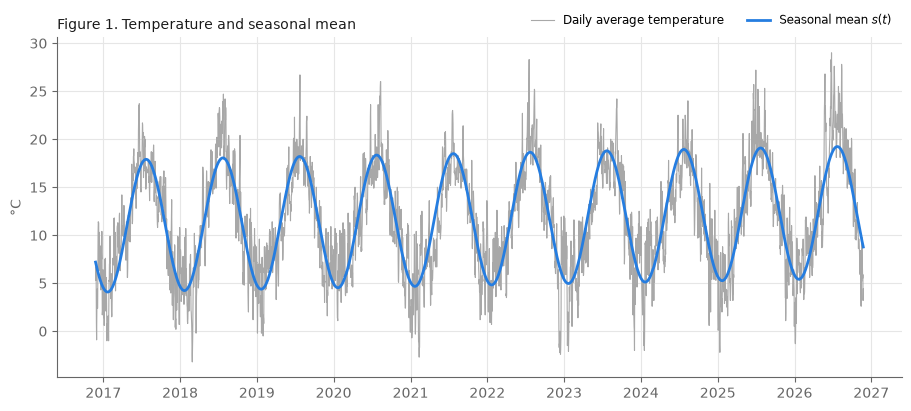

In [4]:
fig = figures.plot_seasonal_mean(result, years=settings.plots.history_years)

What is left after subtracting the mean is the deviation $X(t)$.

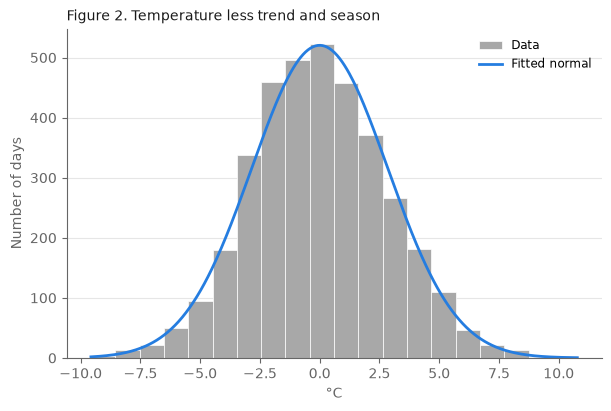

In [5]:
fig = figures.plot_deviation_histogram(result, bins=settings.plots.bins)

## Step 2: mean reversion

Regress each day's deviation on the day before, without a constant. $\alpha$ is the fraction that survives a day; $\kappa = -\log\alpha$ is the speed in the continuous-time equation (1).

In [6]:
parameters[["alpha", "kappa", "residual_std"]].to_frame()

,value
alpha,0.771068
kappa,0.259979
residual_std,1.814090


The residuals themselves are nearly uncorrelated, apart from the first few days, where the paper notes that a higher-order model would help. Their squares follow the seasons, so the variance is not constant. That motivates step 3.

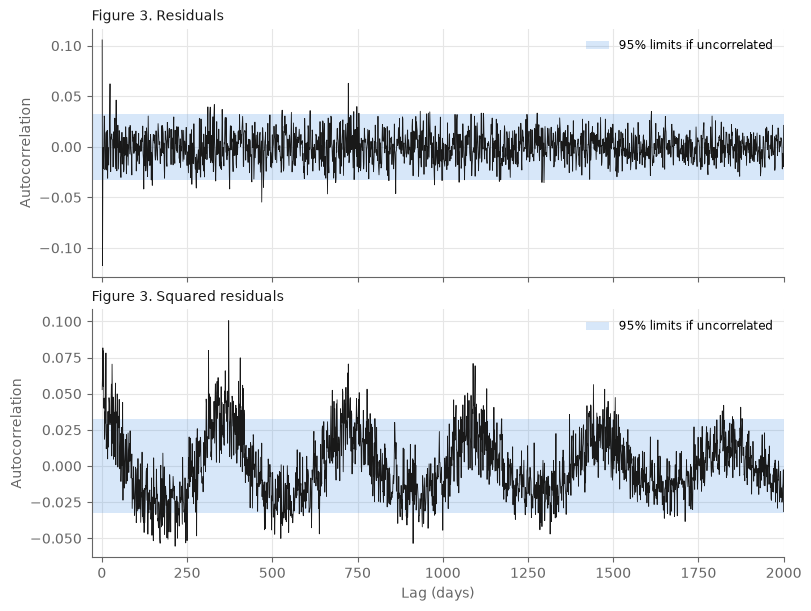

In [7]:
fig = figures.plot_residual_autocorrelation(
    result,
    max_lag=settings.plots.max_lag,
    level=settings.plots.level,
)

## Step 3: daily variance

$$\tilde\sigma^2(t) = \alpha^2 \left[c + \sum_{i=1}^{4} c_i \sin\!\left(\frac{2\pi i t}{365}\right) + \sum_{j=1}^{4} d_j \cos\!\left(\frac{2\pi j t}{365}\right)\right]$$

Take the variance of the residuals for each of the 365 days, then fit the waves to those values. As in the paper's Table 1, the parameters below are for $\sigma^2 = \tilde\sigma^2 / \alpha^2$.

In [8]:
parameters.filter(regex=r"^[cd]\d*$").to_frame()

,value
c,5.453624
c1,-0.233910
c2,-0.410768
c3,-0.330358
c4,-0.175087
d1,2.282729
d2,0.943725
d3,0.013678
d4,0.311802


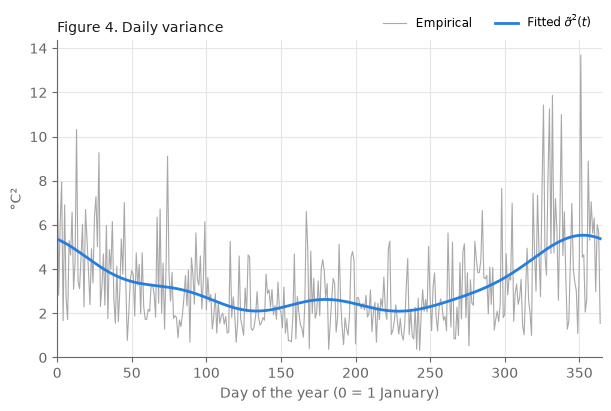

In [18]:
fig = figures.plot_daily_variance(result, figsize=(6,4))

## Check: what is left

Dividing the residuals by $\tilde\sigma(t)$ should leave independent standard normal values: no seasons in the squares (Figure 5) and a bell curve (Figure 6).

The paper's caption for Figure 5 says both panels show squared residuals, before and after dividing. Its text and upper panel show the residuals themselves, so that is what is plotted here.

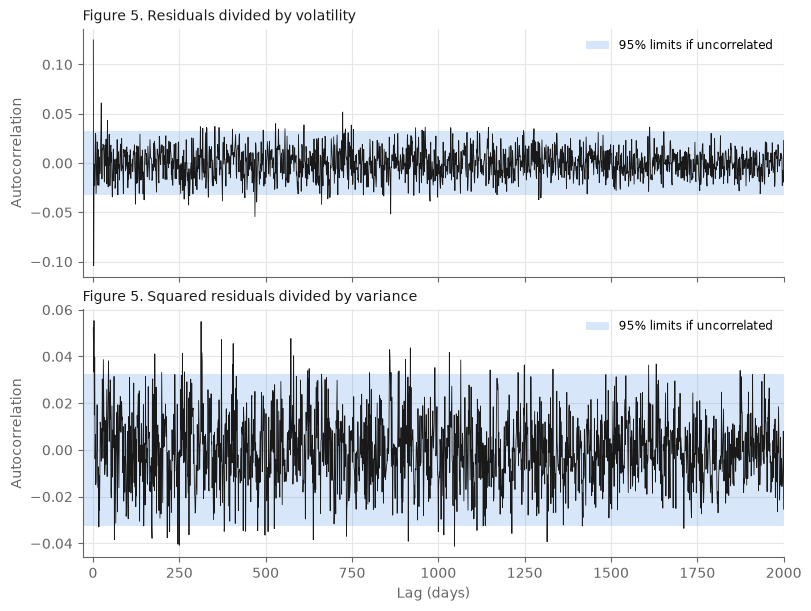

In [10]:
fig = figures.plot_standardised_residual_autocorrelation(
    result,
    max_lag=settings.plots.max_lag,
    level=settings.plots.level,
)

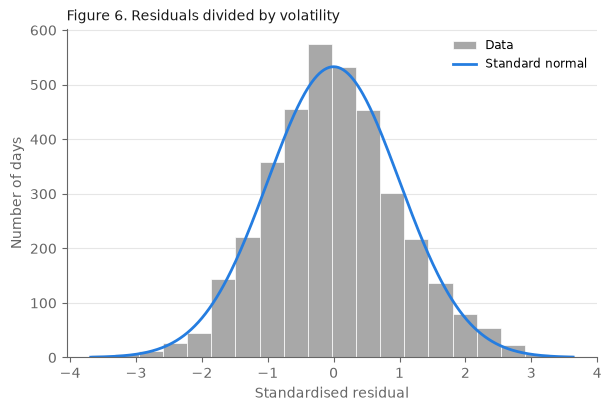

In [11]:
fig = figures.plot_standardised_residual_histogram(
    result,
    bins=settings.plots.bins,
)

In [12]:
pd.DataFrame(
    {
        "Deviation (Figure 2)": normality_summary(result.history["deviation"]),
        "Standardised residual (Figure 6)": normality_summary(
            result.history["standardised_residual"].dropna()
        ),
    }
).round(3)

,Deviation (Figure 2),Standardised residual (Figure 6)
mean,-0.000,-0.002
std,2.847,1.008
skewness,0.127,0.155
kurtosis,0.112,0.276
normality_p_value,0.003,0.000


## Forecast

`predict` gives each day's mean, standard deviation and interval. `sample` gives simulated paths. The interval is for each day's temperature, and does not include uncertainty in the fitted parameters.

The deviation's mean decays as $\alpha^h X(t)$, so after a few weeks the forecast is the seasonal mean. Its variance builds up as $v_h = \alpha^2 v_{h-1} + \tilde\sigma^2(t+h-1)$.

In [13]:
forecast = model.predict(settings.forecast.n_days, level=settings.forecast.level)
forecast

,mean,std,lower,upper
date,,,,
2026-11-25,5.302363,2.203575,0.983436,9.621290
2026-11-26,5.976478,2.790691,0.506825,11.446131
2026-11-27,6.474880,3.094461,0.409847,12.539912
2026-11-28,6.838084,3.268338,0.432260,13.243908
2026-11-29,7.097337,3.373754,0.484902,13.709773
...,...,...,...,...
2027-11-20,9.332219,3.349454,2.767410,15.897028
2027-11-21,9.228607,3.367221,2.628975,15.828239
2027-11-22,9.125981,3.384798,2.491899,15.760064


In [14]:
samples = model.sample(
    settings.forecast.n_days,
    settings.forecast.n_samples,
    random_state=settings.forecast.seed,
)
samples.iloc[:, :5]

sample,0,1,2,3,4
date,,,,,
2026-11-25,5.579419,5.011260,6.713582,5.533518,4.121976
2026-11-26,8.811051,6.424635,7.489797,6.743465,2.041893
2026-11-27,9.592877,5.703536,5.734377,3.507480,-0.295720
2026-11-28,8.374577,5.628272,3.497227,2.746965,1.745113
2026-11-29,10.193218,6.902196,4.259184,6.137023,6.053483
...,...,...,...,...,...
2027-11-20,7.405133,12.457365,9.020634,6.080607,9.291494
2027-11-21,6.881904,13.738541,9.004278,8.976403,9.633010
2027-11-22,3.914343,12.348577,6.321024,6.288199,12.498742


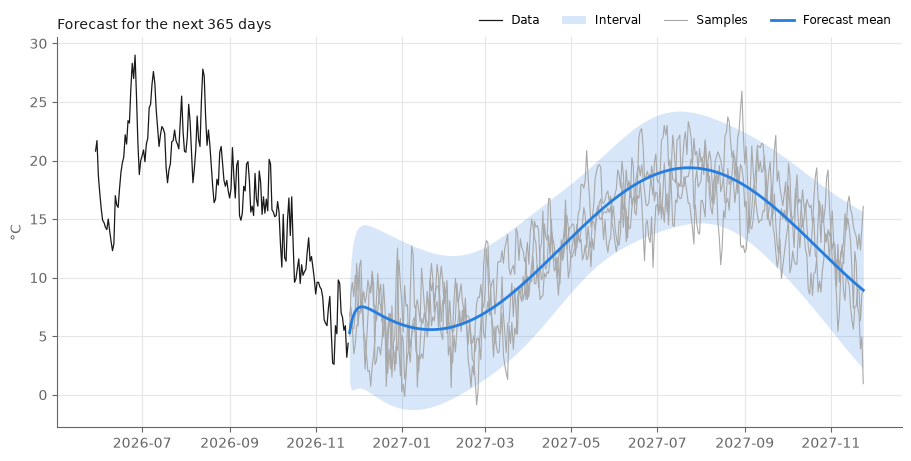

In [15]:
fig = figures.plot_forecast(
    result,
    forecast,
    samples,
    n_paths=settings.plots.n_paths,
    recent_days=settings.plots.recent_days,
)